In [3]:
import pandas as pd

df = pd.read_csv(
    r"C:\Users\cbala\OneDrive\Desktop\Customer-Rescue-AI\data\WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

Dataset loaded successfully!
Number of rows and columns: (7043, 21)


In [7]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [9]:
# Check the number of customers
print("Total customers:", len(df))

# Check the number of columns
print("Total columns:", len(df.columns))

# Display column data types and non-null counts
df.info()

Total customers: 7043
Total columns: 21
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  Pa

In [11]:
# Count missing values in each column
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [13]:
print(df["Churn"].value_counts())

print("\nChurn percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [15]:
# Display the data type
print("Before cleaning:", df["TotalCharges"].dtype)

# Find blank or whitespace-only values
blank_values = df["TotalCharges"].astype(str).str.strip().eq("")

print("Blank TotalCharges values:", blank_values.sum())

# Display the rows containing blank values
df.loc[blank_values, ["customerID", "tenure", "TotalCharges", "Churn"]]

Before cleaning: object
Blank TotalCharges values: 11


,customerID,tenure,TotalCharges,Churn
488,4472-LVYGI,0,,No
753,3115-CZMZD,0,,No
936,5709-LVOEQ,0,,No
1082,4367-NUYAO,0,,No
1340,1371-DWPAZ,0,,No
3331,7644-OMVMY,0,,No
3826,3213-VVOLG,0,,No
4380,2520-SGTTA,0,,No
5218,2923-ARZLG,0,,No
6670,4075-WKNIU,0,,No


In [17]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Check the results
print("Data type after conversion:", df["TotalCharges"].dtype)

print("Missing TotalCharges after conversion:",
      df["TotalCharges"].isnull().sum())

Data type after conversion: float64
Missing TotalCharges after conversion: 11


In [19]:
# Check the number of missing values before cleaning
print("Before cleaning:", df["TotalCharges"].isnull().sum())

# Remove rows with missing TotalCharges
df = df.dropna(subset=["TotalCharges"]).copy()

# Reset the row index
df = df.reset_index(drop=True)

# Verify the cleaning
print("After cleaning:", df["TotalCharges"].isnull().sum())
print("Updated dataset shape:", df.shape)

Before cleaning: 11
After cleaning: 0
Updated dataset shape: (7032, 21)


In [21]:
# Check for completely duplicated rows
print("Duplicate rows:", df.duplicated().sum())

# Check for duplicated customer IDs
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


In [23]:
print(df.dtypes)

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


In [25]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe()

,tenure,MonthlyCharges,TotalCharges
count,7032.000000,7032.000000,7032.000000
mean,32.421786,64.798208,2283.300441
std,24.545260,30.085974,2266.771362
min,1.000000,18.250000,18.800000
25%,9.000000,35.587500,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.862500,3794.737500
max,72.000000,118.750000,8684.800000


In [27]:
print("Churn values:", df["Churn"].unique())
print("Contract types:", df["Contract"].unique())
print("Internet services:", df["InternetService"].unique())
print("SeniorCitizen values:", df["SeniorCitizen"].unique())

Churn values: ['No' 'Yes']
Contract types: ['Month-to-month' 'One year' 'Two year']
Internet services: ['DSL' 'Fiber optic' 'No']
SeniorCitizen values: [0 1]


In [29]:
# Count customers in each churn category
churn_counts = df["Churn"].value_counts()

print("Customer count by churn status:")
print(churn_counts)

# Calculate churn percentage
churn_rate = df["Churn"].value_counts(normalize=True) * 100

print("\nChurn percentage:")
print(churn_rate.round(2))

Customer count by churn status:
Churn
No     5163
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.42
Yes    26.58
Name: proportion, dtype: float64


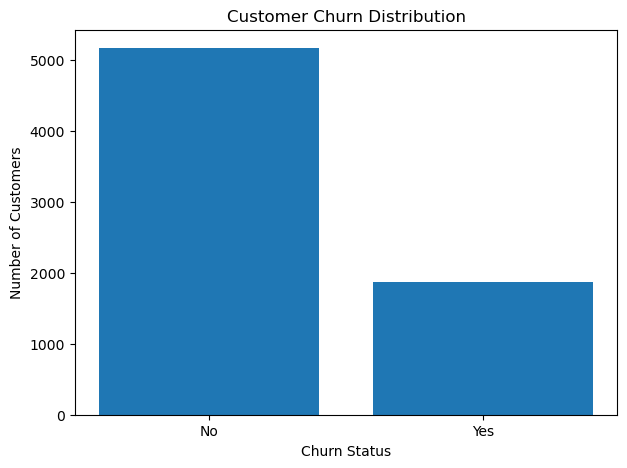

In [31]:
import matplotlib.pyplot as plt

# Count churn categories
churn_counts = df["Churn"].value_counts().reindex(["No", "Yes"])

# Create bar chart
plt.figure(figsize=(7, 5))
plt.bar(churn_counts.index, churn_counts.values)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

In [33]:
# Count customers by contract type and churn status
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

print(contract_churn)

Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1306   166
Two year        1637    48


In [35]:
# Calculate churn percentage within each contract type
contract_churn_rate = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn_rate.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.72  11.28
Two year        97.15   2.85


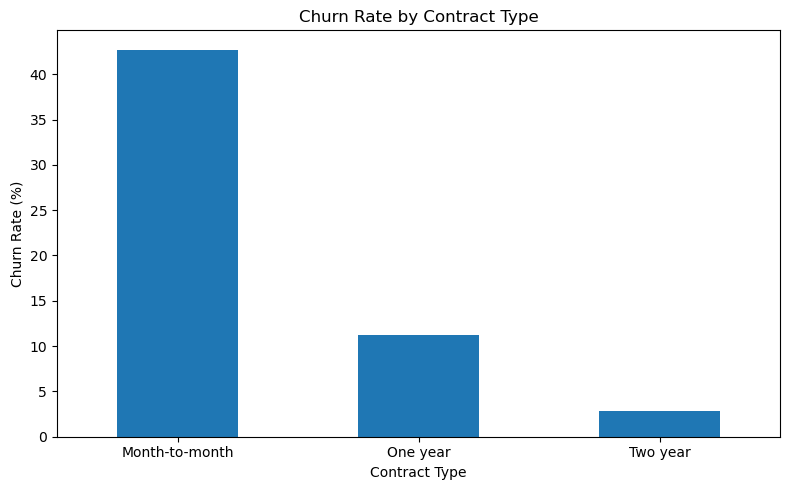

In [37]:
# Extract the churn rate for customers who left
contract_churn_rate["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [39]:
tenure_churn = df.groupby("Churn")["tenure"].agg(
    ["count", "mean", "median"]
)

print(tenure_churn.round(2))

       count   mean  median
Churn                      
No      5163  37.65    38.0
Yes     1869  17.98    10.0


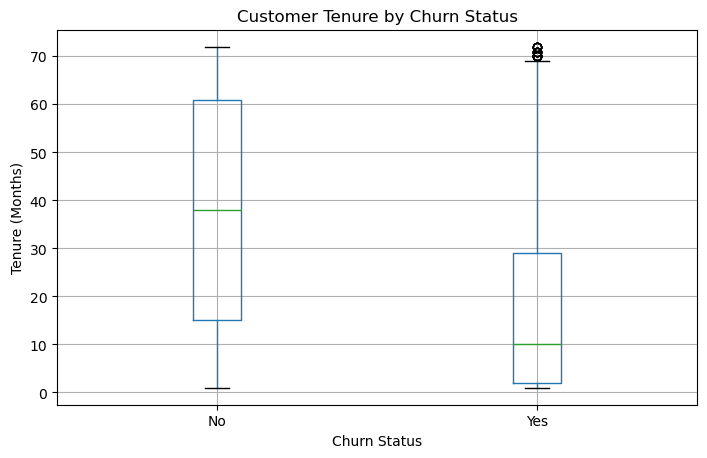

In [41]:
df.boxplot(
    column="tenure",
    by="Churn",
    figsize=(8, 5)
)

plt.title("Customer Tenure by Churn Status")
plt.suptitle("")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")
plt.show()

In [43]:
monthly_charges_churn = df.groupby("Churn")["MonthlyCharges"].agg(
    ["count", "mean", "median"]
)

print(monthly_charges_churn.round(2))

       count   mean  median
Churn                      
No      5163  61.31   64.45
Yes     1869  74.44   79.65


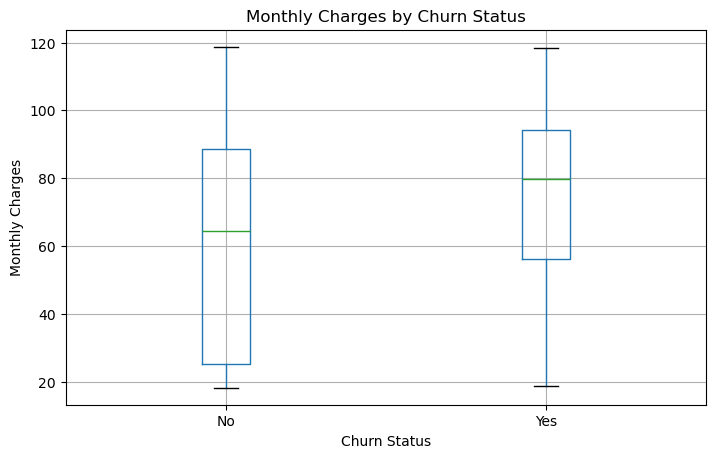

In [45]:
df.boxplot(
    column="MonthlyCharges",
    by="Churn",
    figsize=(8, 5)
)

plt.title("Monthly Charges by Churn Status")
plt.suptitle("")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")
plt.show()

In [47]:
payment_churn_rate = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(payment_churn_rate.round(2))

Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.27  16.73
Credit card (automatic)    84.75  15.25
Electronic check           54.71  45.29
Mailed check               80.80  19.20


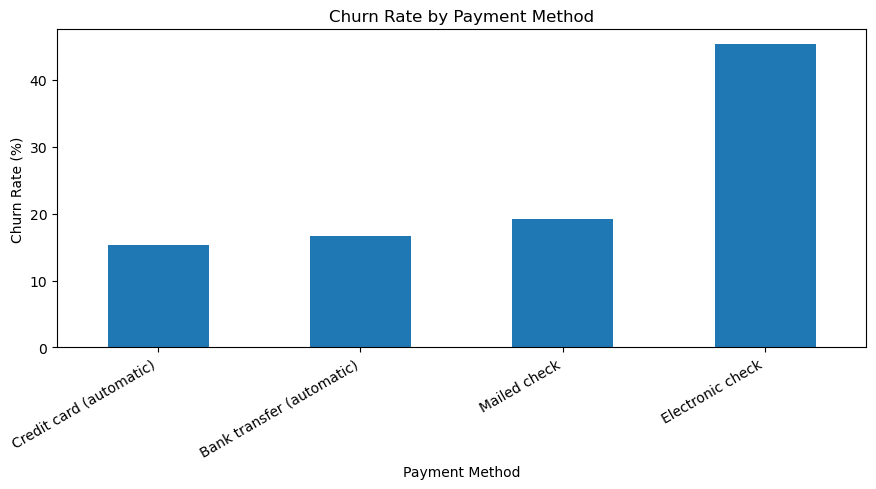

In [49]:
payment_churn_rate["Yes"].sort_values().plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [51]:
internet_churn_rate = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn_rate.round(2))

Churn               No    Yes
InternetService              
DSL              81.00  19.00
Fiber optic      58.11  41.89
No               92.57   7.43


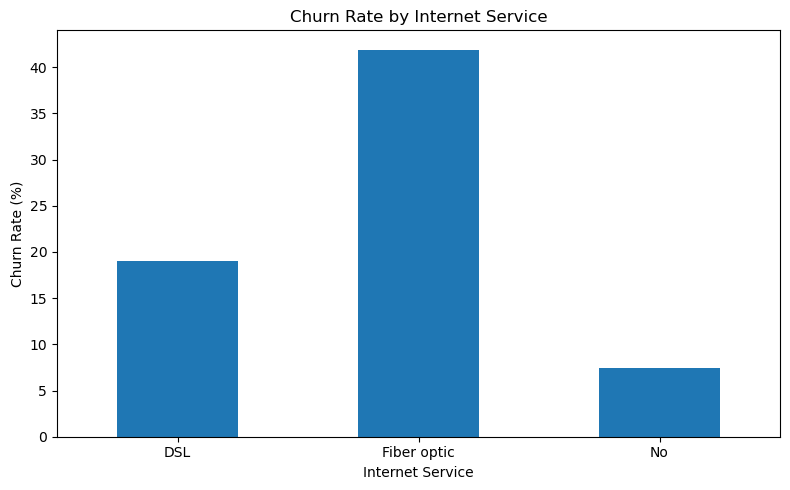

In [53]:
internet_churn_rate["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [55]:
security_churn_rate = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

print(security_churn_rate.round(2))

Churn                   No    Yes
OnlineSecurity                   
No                   58.22  41.78
No internet service  92.57   7.43
Yes                  85.36  14.64


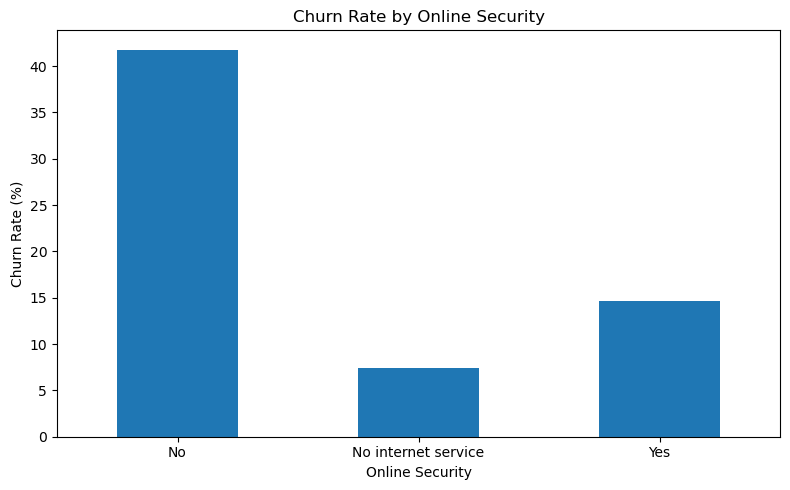

In [57]:
security_churn_rate["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Online Security")
plt.xlabel("Online Security")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [59]:
support_churn_rate = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

print(support_churn_rate.round(2))

Churn                   No    Yes
TechSupport                      
No                   58.35  41.65
No internet service  92.57   7.43
Yes                  84.80  15.20


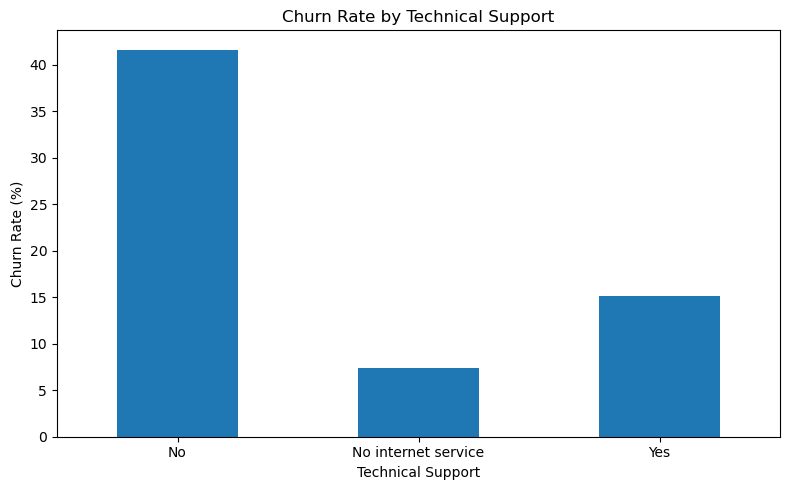

In [61]:
support_churn_rate["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Technical Support")
plt.xlabel("Technical Support")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [63]:
senior_churn_rate = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

print(senior_churn_rate.round(2))

Churn             No    Yes
SeniorCitizen              
0              76.35  23.65
1              58.32  41.68


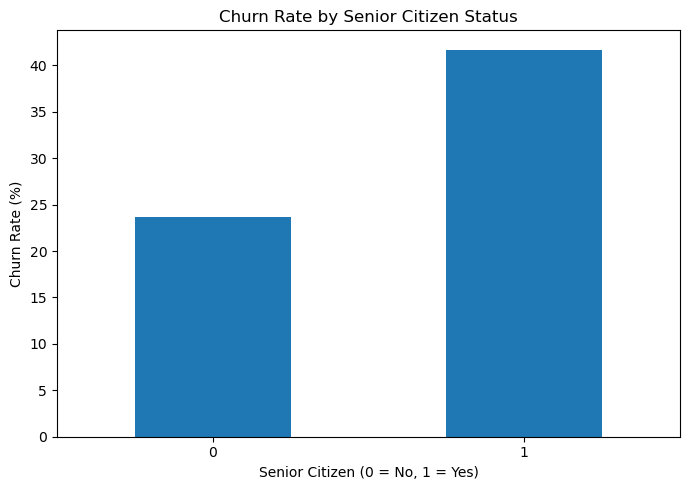

In [65]:
senior_churn_rate["Yes"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Churn Rate by Senior Citizen Status")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [67]:
partner_churn_rate = pd.crosstab(
    df["Partner"],
    df["Churn"],
    normalize="index"
) * 100

print(partner_churn_rate.round(2))

Churn       No    Yes
Partner              
No       67.02  32.98
Yes      80.28  19.72


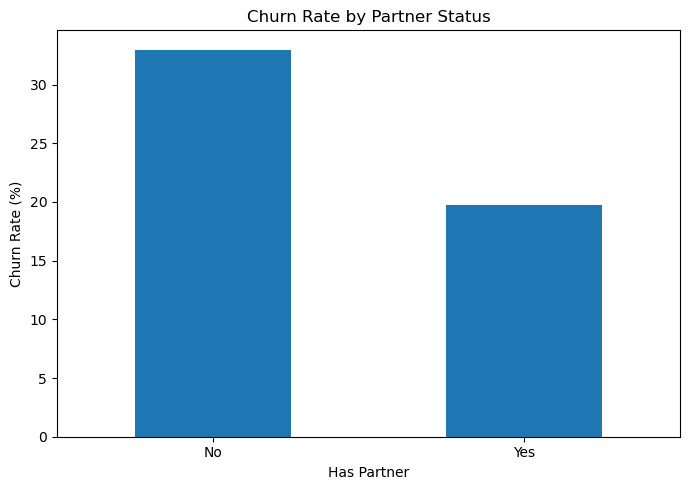

In [69]:
partner_churn_rate["Yes"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Churn Rate by Partner Status")
plt.xlabel("Has Partner")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [71]:
dependents_churn_rate = pd.crosstab(
    df["Dependents"],
    df["Churn"],
    normalize="index"
) * 100

print(dependents_churn_rate.round(2))

Churn          No    Yes
Dependents              
No          68.72  31.28
Yes         84.47  15.53


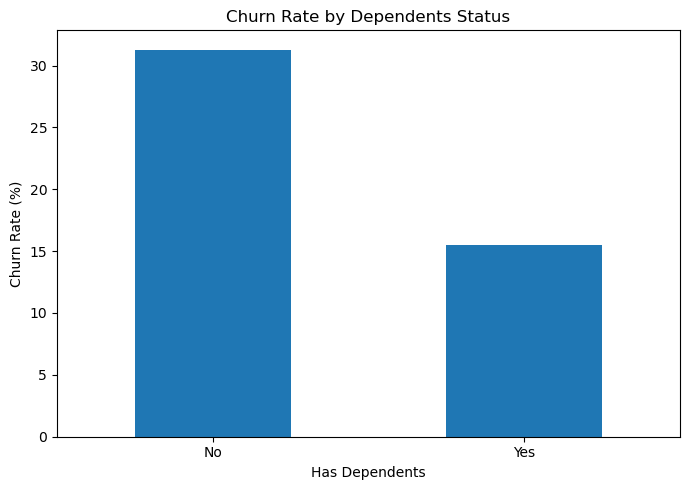

In [73]:
dependents_churn_rate["Yes"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Churn Rate by Dependents Status")
plt.xlabel("Has Dependents")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [75]:
billing_churn_rate = pd.crosstab(
    df["PaperlessBilling"],
    df["Churn"],
    normalize="index"
) * 100

print(billing_churn_rate.round(2))

Churn                No    Yes
PaperlessBilling              
No                83.62  16.38
Yes               66.41  33.59


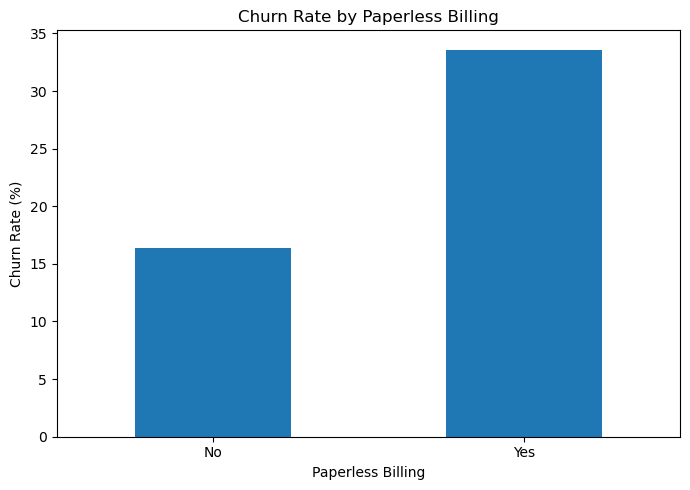

In [77]:
billing_churn_rate["Yes"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Churn Rate by Paperless Billing")
plt.xlabel("Paperless Billing")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [79]:
phone_churn_rate = pd.crosstab(
    df["PhoneService"],
    df["Churn"],
    normalize="index"
) * 100

print(phone_churn_rate.round(2))

Churn            No    Yes
PhoneService              
No            75.00  25.00
Yes           73.25  26.75


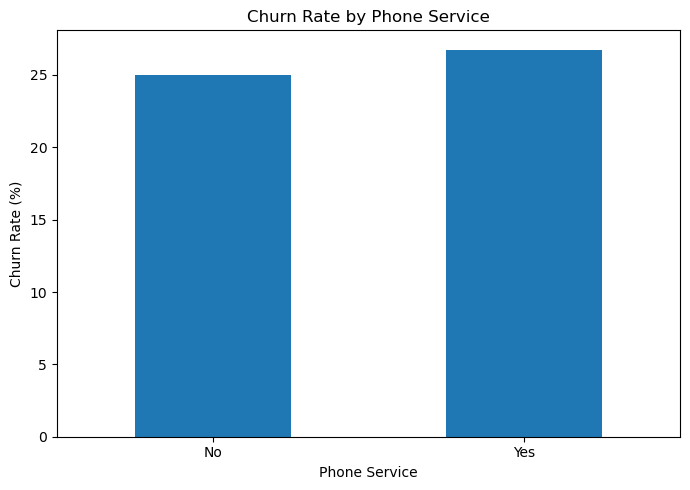

In [81]:
phone_churn_rate["Yes"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Churn Rate by Phone Service")
plt.xlabel("Phone Service")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [83]:
multiple_lines_churn_rate = pd.crosstab(
    df["MultipleLines"],
    df["Churn"],
    normalize="index"
) * 100

print(multiple_lines_churn_rate.round(2))

Churn                No    Yes
MultipleLines                 
No                74.92  25.08
No phone service  75.00  25.00
Yes               71.35  28.65


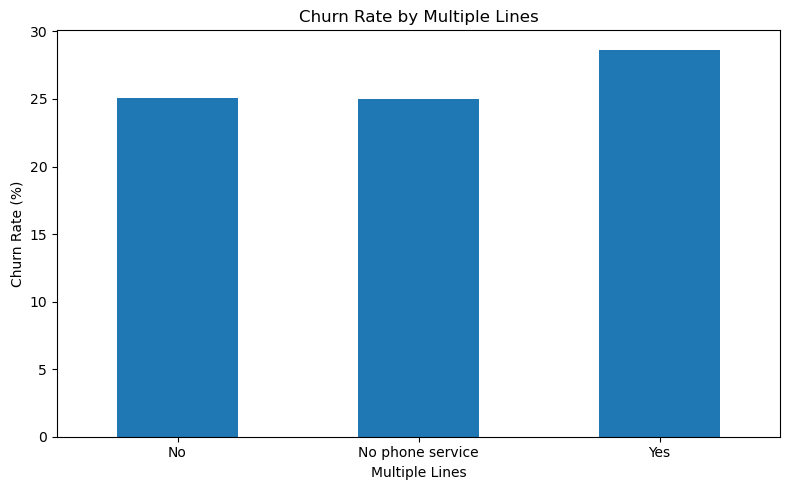

In [85]:
multiple_lines_churn_rate["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Multiple Lines")
plt.xlabel("Multiple Lines")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [87]:
backup_churn_rate = pd.crosstab(
    df["OnlineBackup"],
    df["Churn"],
    normalize="index"
) * 100

print(backup_churn_rate.round(2))

Churn                   No    Yes
OnlineBackup                     
No                   60.06  39.94
No internet service  92.57   7.43
Yes                  78.43  21.57


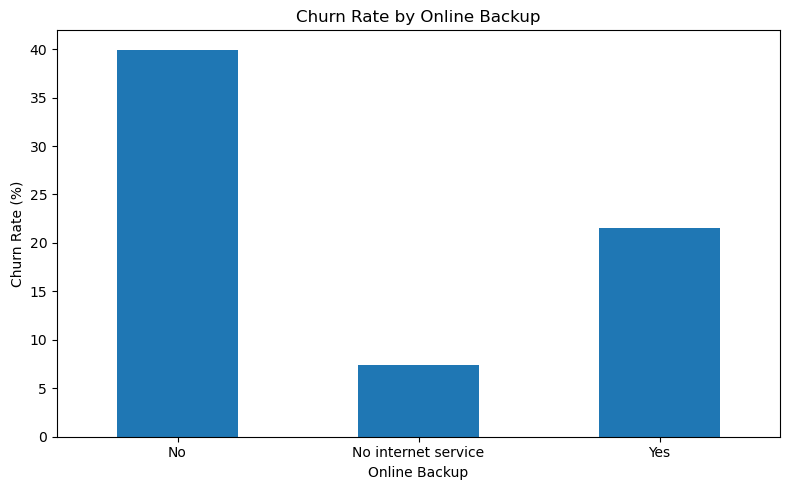

In [89]:
backup_churn_rate["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Online Backup")
plt.xlabel("Online Backup")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [91]:
device_churn_rate = pd.crosstab(
    df["DeviceProtection"],
    df["Churn"],
    normalize="index"
) * 100

print(device_churn_rate.round(2))

Churn                   No    Yes
DeviceProtection                 
No                   60.86  39.14
No internet service  92.57   7.43
Yes                  77.46  22.54


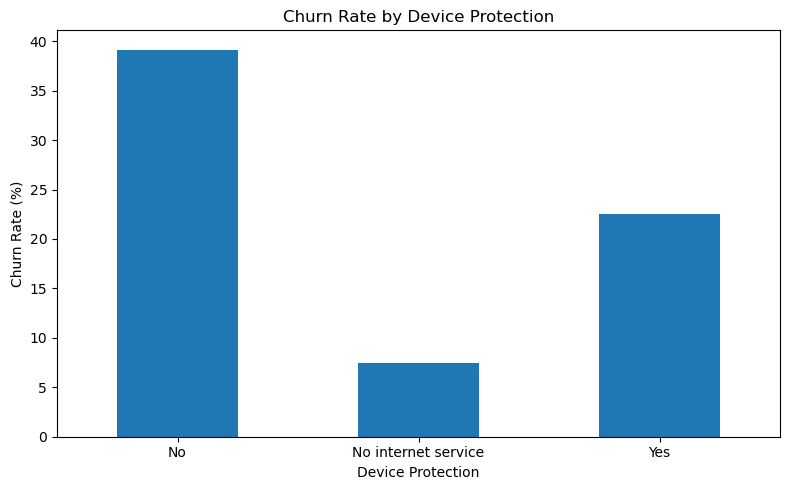

In [93]:
device_churn_rate["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Device Protection")
plt.xlabel("Device Protection")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [95]:
streaming_tv_churn_rate = pd.crosstab(
    df["StreamingTV"],
    df["Churn"],
    normalize="index"
) * 100

print(streaming_tv_churn_rate.round(2))

Churn                   No    Yes
StreamingTV                      
No                   66.46  33.54
No internet service  92.57   7.43
Yes                  69.89  30.11


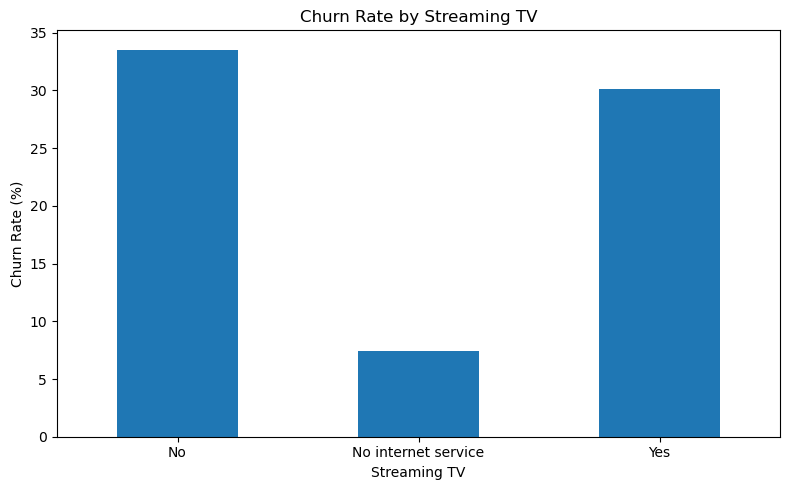

In [97]:
streaming_tv_churn_rate["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Streaming TV")
plt.xlabel("Streaming TV")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [99]:
streaming_movies_churn_rate = pd.crosstab(
    df["StreamingMovies"],
    df["Churn"],
    normalize="index"
) * 100

print(streaming_movies_churn_rate.round(2))

Churn                   No    Yes
StreamingMovies                  
No                   66.27  33.73
No internet service  92.57   7.43
Yes                  70.05  29.95


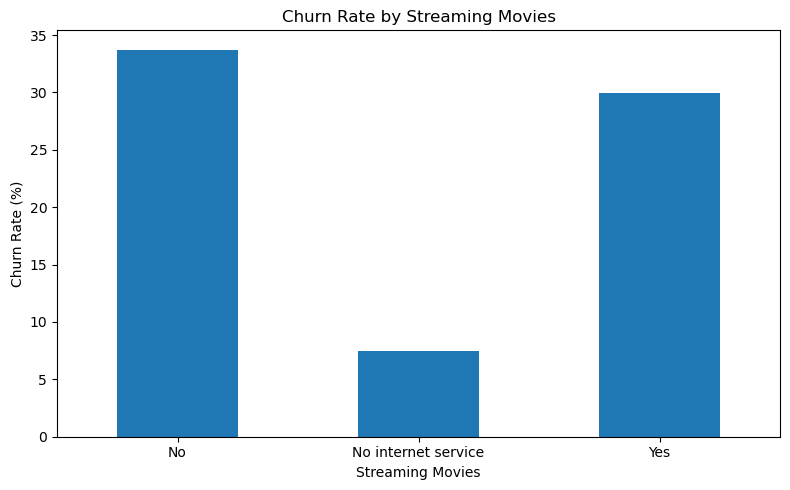

In [101]:
streaming_movies_churn_rate["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Streaming Movies")
plt.xlabel("Streaming Movies")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [103]:
gender_churn_rate = pd.crosstab(
    df["gender"],
    df["Churn"],
    normalize="index"
) * 100

print(gender_churn_rate.round(2))

Churn      No    Yes
gender              
Female  73.04  26.96
Male    73.80  26.20


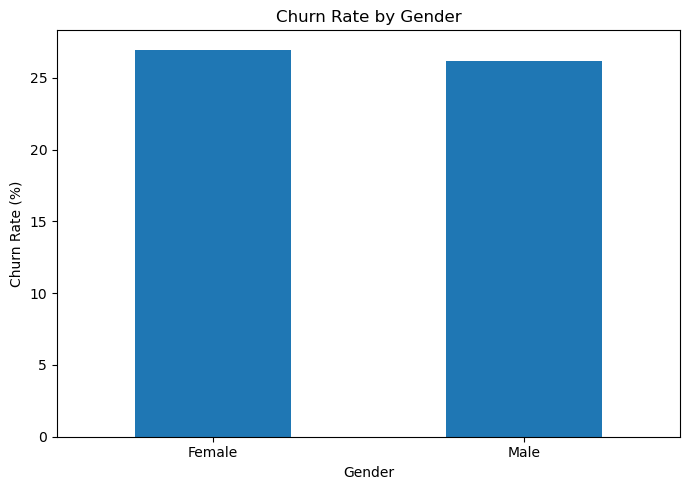

In [105]:
gender_churn_rate["Yes"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [107]:
eda_summary = pd.DataFrame({
    "Factor": [
        "Contract Type",
        "Tenure",
        "Monthly Charges",
        "Payment Method",
        "Internet Service",
        "Online Security",
        "Technical Support",
        "Senior Citizen",
        "Online Backup",
        "Device Protection"
    ],
    "Key Finding": [
        "Month-to-month: 42.71% churn",
        "Churned median tenure: 10 months",
        "Churned average: 74.44",
        "Electronic check: 45.29% churn",
        "Fiber optic: 41.89% churn",
        "No security: 41.78% churn",
        "No support: 41.65% churn",
        "Senior citizens: 41.68% churn",
        "No backup: 39.94% churn",
        "No protection: 39.14% churn"
    ]
})

eda_summary

,Factor,Key Finding
0,Contract Type,Month-to-month: 42.71% churn
1,Tenure,Churned median tenure: 10 months
2,Monthly Charges,Churned average: 74.44
3,Payment Method,Electronic check: 45.29% churn
4,Internet Service,Fiber optic: 41.89% churn
5,Online Security,No security: 41.78% churn
6,Technical Support,No support: 41.65% churn
7,Senior Citizen,Senior citizens: 41.68% churn
8,Online Backup,No backup: 39.94% churn
9,Device Protection,No protection: 39.14% churn


In [109]:
cleaned_file_path = (
    r"C:\Users\cbala\OneDrive\Desktop"
    r"\Customer-Rescue-AI\data\cleaned_customer_churn.csv"
)

df.to_csv(cleaned_file_path, index=False)

print("Cleaned dataset saved successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("File:", cleaned_file_path)

Cleaned dataset saved successfully!
Rows: 7032
Columns: 21
File: C:\Users\cbala\OneDrive\Desktop\Customer-Rescue-AI\data\cleaned_customer_churn.csv


In [111]:
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print(df["Churn"].value_counts())
print("\nChurn percentages:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

Churn
0    5163
1    1869
Name: count, dtype: int64

Churn percentages:
Churn
0    73.42
1    26.58
Name: proportion, dtype: float64


In [113]:
# Separate input features and target variable

X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget sample:")
print(y.head())

Features shape: (7032, 19)
Target shape: (7032,)

Feature columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

Target sample:
0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64


In [115]:
# Identify numerical and categorical columns

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("\nNumber of numerical features:", len(numerical_features))

print("\nCategorical features:", categorical_features)
print("\nNumber of categorical features:", len(categorical_features))

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Number of numerical features: 4

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of categorical features: 15


In [117]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (5625, 19)
Testing features: (1407, 19)

Training target distribution:
Churn
0    4130
1    1495
Name: count, dtype: int64

Testing target distribution:
Churn
0    1033
1     374
Name: count, dtype: int64


In [119]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

print("Preprocessing tools imported successfully!")

Preprocessing tools imported successfully!


In [121]:
# Process numerical features
numerical_transformer = StandardScaler()

# Process categorical features
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine both preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [123]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

Training data after preprocessing: (5625, 45)
Testing data after preprocessing: (1407, 45)


In [125]:
from sklearn.linear_model import LogisticRegression

print("Logistic Regression imported successfully!")

Logistic Regression imported successfully!


In [127]:
# Create the model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train using the processed training data
logistic_model.fit(
    X_train_processed,
    y_train
)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [129]:
# Predict churn for test customers
y_pred = logistic_model.predict(X_test_processed)

print("First 20 actual churn values:")
print(y_test.head(20).tolist())

print("\nFirst 20 predicted churn values:")
print(y_pred[:20])


First 20 actual churn values:
[0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0]

First 20 predicted churn values:
[0 1 0 0 0 0 0 0 1 0 1 0 1 0 0 1 1 1 0 0]


In [131]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.2%}")

Model Accuracy: 80.38%


In [133]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Churned"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1033
     Churned       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407

Confusion Matrix:
[[917 116]
 [160 214]]


In [135]:
# Get the probability of each test customer churning
y_prob = logistic_model.predict_proba(X_test_processed)[:, 1]

print("First 10 churn probabilities:")
print(y_prob[:10])

First 10 churn probabilities:
[0.01751303 0.59192131 0.00482103 0.20165167 0.1015014  0.4718449
 0.02651812 0.16543101 0.67959955 0.01552463]


In [137]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.50, 0.40, 0.30]

for threshold in thresholds:
    y_threshold_pred = (y_prob >= threshold).astype(int)

    precision = precision_score(y_test, y_threshold_pred)
    recall = recall_score(y_test, y_threshold_pred)
    f1 = f1_score(y_test, y_threshold_pred)

    print(f"\nThreshold: {threshold}")
    print(f"Precision: {precision:.2%}")
    print(f"Recall:    {recall:.2%}")
    print(f"F1-score:  {f1:.2%}")


Threshold: 0.5
Precision: 64.85%
Recall:    57.22%
F1-score:  60.80%

Threshold: 0.4
Precision: 57.92%
Recall:    68.45%
F1-score:  62.75%

Threshold: 0.3
Precision: 51.08%
Recall:    75.94%
F1-score:  61.08%


In [139]:
from sklearn.metrics import confusion_matrix, classification_report

# Use our selected threshold
best_threshold = 0.40

y_pred_40 = (y_prob >= best_threshold).astype(int)

# Display confusion matrix
cm_40 = confusion_matrix(y_test, y_pred_40)

print("Confusion Matrix at Threshold 0.40:")
print(cm_40)

print("\nClassification Report at Threshold 0.40:")
print(classification_report(
    y_test,
    y_pred_40,
    target_names=["Stayed", "Churned"]
))

Confusion Matrix at Threshold 0.40:
[[847 186]
 [118 256]]

Classification Report at Threshold 0.40:
              precision    recall  f1-score   support

      Stayed       0.88      0.82      0.85      1033
     Churned       0.58      0.68      0.63       374

    accuracy                           0.78      1407
   macro avg       0.73      0.75      0.74      1407
weighted avg       0.80      0.78      0.79      1407



In [141]:
from sklearn.ensemble import RandomForestClassifier

print("Random Forest imported successfully!")

Random Forest imported successfully!


In [143]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=4,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [145]:
# Predict churn using Random Forest
rf_pred = rf_model.predict(X_test_processed)

# Get the probability of churn
rf_prob = rf_model.predict_proba(X_test_processed)[:, 1]

print("First 20 Random Forest predictions:")
print(rf_pred[:20])

First 20 Random Forest predictions:
[0 1 0 0 0 1 0 0 1 0 1 0 1 0 0 1 1 1 0 0]


In [147]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Random Forest Accuracy:",
      f"{accuracy_score(y_test, rf_pred):.2%}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["Stayed", "Churned"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

Random Forest Accuracy: 76.62%

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.89      0.77      0.83      1033
     Churned       0.54      0.75      0.63       374

    accuracy                           0.77      1407
   macro avg       0.72      0.76      0.73      1407
weighted avg       0.80      0.77      0.78      1407

Confusion Matrix:
[[798 235]
 [ 94 280]]


In [149]:
from sklearn.metrics import precision_score, recall_score, f1_score

comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Churn Precision": precision_score(y_test, y_pred),
        "Churn Recall": recall_score(y_test, y_pred),
        "Churn F1-Score": f1_score(y_test, y_pred)
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_pred),
        "Churn Precision": precision_score(y_test, rf_pred),
        "Churn Recall": recall_score(y_test, rf_pred),
        "Churn F1-Score": f1_score(y_test, rf_pred)
    }
])

comparison.set_index("Model").style.format("{:.2%}")

,Accuracy,Churn Precision,Churn Recall,Churn F1-Score
Model,,,,
Logistic Regression,80.38%,64.85%,57.22%,60.80%
Random Forest,76.62%,54.37%,74.87%,62.99%


In [151]:
from sklearn.metrics import precision_score, recall_score, f1_score

rf_threshold_results = []

for threshold in [0.50, 0.40, 0.30]:
    rf_threshold_pred = (rf_prob >= threshold).astype(int)

    rf_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, rf_threshold_pred),
        "Recall": recall_score(y_test, rf_threshold_pred),
        "F1-Score": f1_score(y_test, rf_threshold_pred)
    })

rf_threshold_df = pd.DataFrame(rf_threshold_results)

rf_threshold_df.style.format({
    "Threshold": "{:.2f}",
    "Precision": "{:.2%}",
    "Recall": "{:.2%}",
    "F1-Score": "{:.2%}"
})

,Threshold,Precision,Recall,F1-Score
0,0.50,54.37%,74.87%,62.99%
1,0.40,49.12%,81.82%,61.38%
2,0.30,44.17%,87.17%,58.63%


In [153]:
# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get Random Forest feature importance
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

# Sort from most important to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display the top 15 features
feature_importance.head(15)

,Feature,Importance
0,num__tenure,0.129596
1,cat__Contract_Month-to-month,0.127746
2,num__TotalCharges,0.100780
3,num__MonthlyCharges,0.075981
4,cat__Contract_Two year,0.061497
5,cat__OnlineSecurity_No,0.057703
6,cat__TechSupport_No,0.048398
7,cat__InternetService_Fiber optic,0.041742
8,cat__PaymentMethod_Electronic check,0.035997
9,cat__OnlineBackup_No,0.019542


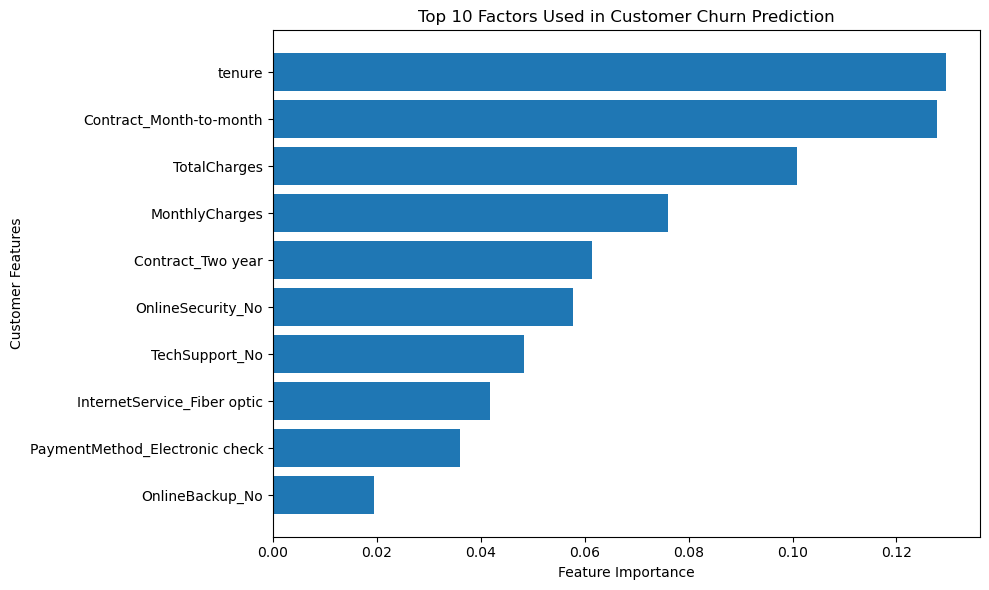

In [155]:
import matplotlib.pyplot as plt

# Select the top 10 features
top_features = feature_importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"].str.replace(
        "num__", "", regex=False
    ).str.replace(
        "cat__", "", regex=False
    ),
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Customer Features")
plt.title("Top 10 Factors Used in Customer Churn Prediction")
plt.tight_layout()

plt.show()

In [157]:
# Create a customer risk table using the test dataset
customer_risk = X_test.copy()

# Add actual churn status
customer_risk["Actual_Churn"] = y_test

# Add predicted churn probability
customer_risk["Churn_Probability"] = rf_prob

# Add predicted churn status using threshold 0.50
customer_risk["Predicted_Churn"] = (rf_prob >= 0.50).astype(int)

# Assign risk categories
customer_risk["Risk_Level"] = pd.cut(
    customer_risk["Churn_Probability"],
    bins=[-0.001, 0.30, 0.60, 1.0],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

# Display highest-risk customers first
customer_risk = customer_risk.sort_values(
    by="Churn_Probability",
    ascending=False
)

customer_risk.head(10)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Churn_Probability,Predicted_Churn,Risk_Level
3374,Male,1,Yes,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,95.10,95.10,1,0.956158,1,High Risk
3154,Male,1,No,No,3,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,94.85,335.75,0,0.955827,1,High Risk
2792,Male,0,No,No,3,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,100.95,329.95,1,0.950129,1,High Risk
4577,Female,1,No,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,85.05,85.05,1,0.948773,1,High Risk
3721,Female,0,No,No,3,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,96.60,291.90,1,0.946868,1,High Risk
2626,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,99.25,665.45,1,0.944267,1,High Risk
807,Male,0,No,No,1,Yes,No,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,69.55,69.55,1,0.943429,1,High Risk
3676,Male,0,No,No,1,Yes,No,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,69.10,69.10,1,0.939937,1,High Risk
1734,Male,0,No,No,1,Yes,No,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,69.90,69.90,1,0.937589,1,High Risk
2922,Male,0,No,No,1,Yes,No,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,69.90,69.90,0,0.937589,1,High Risk


In [159]:
# Create a copy of the customer risk table
customer_risk = customer_risk.copy()

# Add original customer IDs using the matching row indexes
customer_risk["customerID"] = df.loc[
    customer_risk.index, "customerID"
]

# Move customerID to the first column
customer_risk = customer_risk[
    ["customerID"] +
    [col for col in customer_risk.columns if col != "customerID"]
]

# Display the 10 highest-risk customers
customer_risk.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Churn_Probability,Predicted_Churn,Risk_Level
3374,5178-LMXOP,Male,1,Yes,No,1,Yes,Yes,Fiber optic,No,...,Yes,Month-to-month,Yes,Electronic check,95.10,95.10,1,0.956158,1,High Risk
3154,5150-ITWWB,Male,1,No,No,3,Yes,Yes,Fiber optic,No,...,Yes,Month-to-month,Yes,Electronic check,94.85,335.75,0,0.955827,1,High Risk
2792,6023-YEBUP,Male,0,No,No,3,Yes,Yes,Fiber optic,No,...,Yes,Month-to-month,Yes,Electronic check,100.95,329.95,1,0.950129,1,High Risk
4577,1069-XAIEM,Female,1,No,No,1,Yes,Yes,Fiber optic,No,...,Yes,Month-to-month,Yes,Electronic check,85.05,85.05,1,0.948773,1,High Risk
3721,9057-SIHCH,Female,0,No,No,3,Yes,Yes,Fiber optic,No,...,Yes,Month-to-month,Yes,Electronic check,96.60,291.90,1,0.946868,1,High Risk
2626,6861-XWTWQ,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,...,Yes,Month-to-month,Yes,Electronic check,99.25,665.45,1,0.944267,1,High Risk
807,1820-TQVEV,Male,0,No,No,1,Yes,No,Fiber optic,No,...,No,Month-to-month,Yes,Electronic check,69.55,69.55,1,0.943429,1,High Risk
3676,3716-BDVDB,Male,0,No,No,1,Yes,No,Fiber optic,No,...,No,Month-to-month,Yes,Electronic check,69.10,69.10,1,0.939937,1,High Risk
1734,9804-ICWBG,Male,0,No,No,1,Yes,No,Fiber optic,No,...,No,Month-to-month,Yes,Electronic check,69.90,69.90,1,0.937589,1,High Risk
2922,5542-TBBWB,Male,0,No,No,1,Yes,No,Fiber optic,No,...,No,Month-to-month,Yes,Electronic check,69.90,69.90,0,0.937589,1,High Risk


In [161]:
# Count customers in each risk category
risk_summary = customer_risk.groupby(
    "Risk_Level", observed=False
).agg(
    Total_Customers=("customerID", "count"),
    Actual_Churners=("Actual_Churn", "sum"),
    Average_Churn_Probability=("Churn_Probability", "mean")
).reset_index()

# Calculate percentage of actual churners within each risk category
risk_summary["Actual_Churn_Rate_%"] = (
    risk_summary["Actual_Churners"]
    / risk_summary["Total_Customers"] * 100
).round(2)

# Format probability as percentage
risk_summary["Average_Churn_Probability_%"] = (
    risk_summary["Average_Churn_Probability"] * 100
).round(2)

risk_summary = risk_summary.drop(
    columns=["Average_Churn_Probability"]
)

risk_summary

,Risk_Level,Total_Customers,Actual_Churners,Actual_Churn_Rate_%,Average_Churn_Probability_%
0,Low Risk,669,48,7.17,10.91
1,Medium Risk,358,102,28.49,45.50
2,High Risk,380,224,58.95,77.16


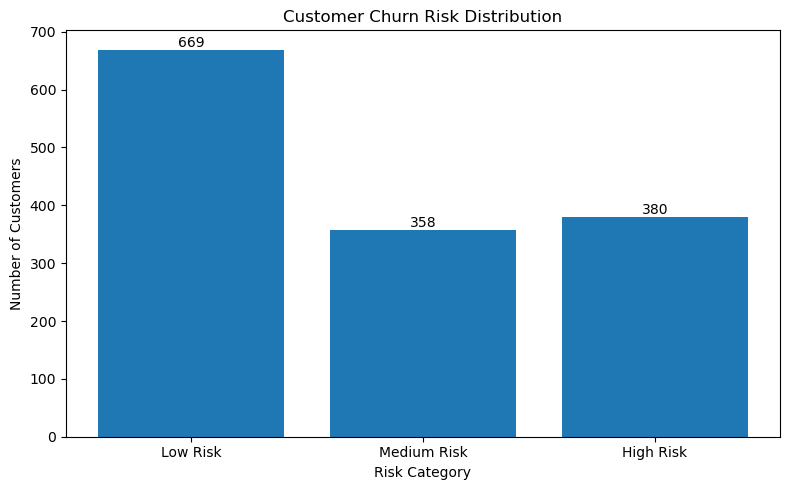

In [163]:
import matplotlib.pyplot as plt

risk_counts = customer_risk["Risk_Level"].value_counts()

risk_order = ["Low Risk", "Medium Risk", "High Risk"]
risk_counts = risk_counts.reindex(risk_order, fill_value=0)

plt.figure(figsize=(8, 5))
plt.bar(risk_counts.index, risk_counts.values)

plt.title("Customer Churn Risk Distribution")
plt.xlabel("Risk Category")
plt.ylabel("Number of Customers")

for i, value in enumerate(risk_counts.values):
    plt.text(i, value + 5, str(value), ha="center")

plt.tight_layout()
plt.show()

In [165]:
# Create a copy of the customer risk table
customer_risk = customer_risk.copy()

# Assign retention recommendations
retention_actions = {
    "Low Risk": "Regular engagement and loyalty benefits",
    "Medium Risk": "Send feedback survey and personalized offers",
    "High Risk": "Priority retention call and tailored discount"
}

customer_risk["Retention_Action"] = (
    customer_risk["Risk_Level"]
    .astype(str)
    .map(retention_actions)
)

# Display the highest-risk customers and their recommended actions
customer_risk[
    [
        "customerID",
        "tenure",
        "Contract",
        "MonthlyCharges",
        "Churn_Probability",
        "Risk_Level",
        "Retention_Action"
    ]
].head(10)

,customerID,tenure,Contract,MonthlyCharges,Churn_Probability,Risk_Level,Retention_Action
3374,5178-LMXOP,1,Month-to-month,95.10,0.956158,High Risk,Priority retention call and tailored discount
3154,5150-ITWWB,3,Month-to-month,94.85,0.955827,High Risk,Priority retention call and tailored discount
2792,6023-YEBUP,3,Month-to-month,100.95,0.950129,High Risk,Priority retention call and tailored discount
4577,1069-XAIEM,1,Month-to-month,85.05,0.948773,High Risk,Priority retention call and tailored discount
3721,9057-SIHCH,3,Month-to-month,96.60,0.946868,High Risk,Priority retention call and tailored discount
2626,6861-XWTWQ,7,Month-to-month,99.25,0.944267,High Risk,Priority retention call and tailored discount
807,1820-TQVEV,1,Month-to-month,69.55,0.943429,High Risk,Priority retention call and tailored discount
3676,3716-BDVDB,1,Month-to-month,69.10,0.939937,High Risk,Priority retention call and tailored discount
1734,9804-ICWBG,1,Month-to-month,69.90,0.937589,High Risk,Priority retention call and tailored discount
2922,5542-TBBWB,1,Month-to-month,69.90,0.937589,High Risk,Priority retention call and tailored discount


In [167]:
import os
import joblib

# Project model folder
model_folder = (
    r"C:\Users\cbala\OneDrive\Desktop"
    r"\Customer-Rescue-AI\models"
)

# Create the folder if it does not exist
os.makedirs(model_folder, exist_ok=True)

# Save the trained model and preprocessing pipeline
joblib.dump(
    rf_model,
    os.path.join(model_folder, "random_forest_churn_model.pkl")
)

joblib.dump(
    preprocessor,
    os.path.join(model_folder, "churn_preprocessor.pkl")
)

print("Model and preprocessor saved successfully!")
print("Model folder:", model_folder)

Model and preprocessor saved successfully!
Model folder: C:\Users\cbala\OneDrive\Desktop\Customer-Rescue-AI\models


In [169]:
import os

# Create the reports folder if needed
reports_folder = (
    r"C:\Users\cbala\OneDrive\Desktop"
    r"\Customer-Rescue-AI\reports"
)
os.makedirs(reports_folder, exist_ok=True)

# Create a clean report without the DataFrame index
report_columns = [
    "customerID",
    "Actual_Churn",
    "Churn_Probability",
    "Predicted_Churn",
    "Risk_Level",
    "Retention_Action",
    "tenure",
    "Contract",
    "MonthlyCharges",
    "TotalCharges"
]

final_report = customer_risk[report_columns].copy()

# Convert probability to a percentage for easier business interpretation
final_report["Churn_Probability_%"] = (
    final_report["Churn_Probability"] * 100
).round(2)

# Sort highest-risk customers first
final_report = final_report.sort_values(
    by="Churn_Probability",
    ascending=False
)

# Save report
report_path = os.path.join(
    reports_folder,
    "customer_churn_risk_report.csv"
)

final_report.to_csv(report_path, index=False)

print("Customer risk report exported successfully!")
print("Report location:", report_path)
print("Report shape:", final_report.shape)

final_report.head(10)

Customer risk report exported successfully!
Report location: C:\Users\cbala\OneDrive\Desktop\Customer-Rescue-AI\reports\customer_churn_risk_report.csv
Report shape: (1407, 11)


,customerID,Actual_Churn,Churn_Probability,Predicted_Churn,Risk_Level,Retention_Action,tenure,Contract,MonthlyCharges,TotalCharges,Churn_Probability_%
3374,5178-LMXOP,1,0.956158,1,High Risk,Priority retention call and tailored discount,1,Month-to-month,95.10,95.10,95.62
3154,5150-ITWWB,0,0.955827,1,High Risk,Priority retention call and tailored discount,3,Month-to-month,94.85,335.75,95.58
2792,6023-YEBUP,1,0.950129,1,High Risk,Priority retention call and tailored discount,3,Month-to-month,100.95,329.95,95.01
4577,1069-XAIEM,1,0.948773,1,High Risk,Priority retention call and tailored discount,1,Month-to-month,85.05,85.05,94.88
3721,9057-SIHCH,1,0.946868,1,High Risk,Priority retention call and tailored discount,3,Month-to-month,96.60,291.90,94.69
2626,6861-XWTWQ,1,0.944267,1,High Risk,Priority retention call and tailored discount,7,Month-to-month,99.25,665.45,94.43
807,1820-TQVEV,1,0.943429,1,High Risk,Priority retention call and tailored discount,1,Month-to-month,69.55,69.55,94.34
3676,3716-BDVDB,1,0.939937,1,High Risk,Priority retention call and tailored discount,1,Month-to-month,69.10,69.10,93.99
1734,9804-ICWBG,1,0.937589,1,High Risk,Priority retention call and tailored discount,1,Month-to-month,69.90,69.90,93.76
2922,5542-TBBWB,0,0.937589,1,High Risk,Priority retention call and tailored discount,1,Month-to-month,69.90,69.90,93.76


In [171]:
import pandas as pd
import os

report_path = (
    r"C:\Users\cbala\OneDrive\Desktop"
    r"\Customer-Rescue-AI\reports\customer_churn_risk_report.csv"
)

# Read the saved CSV
check_report = pd.read_csv(report_path)

# Verify file and structure
print("File exists:", os.path.exists(report_path))
print("Report shape:", check_report.shape)
print("\nColumn names:")
print(check_report.columns.tolist())

print("\nMissing values:")
print(check_report.isnull().sum())

print("\nFirst 5 rows:")
display(check_report.head())

File exists: True
Report shape: (1407, 11)

Column names:
['customerID', 'Actual_Churn', 'Churn_Probability', 'Predicted_Churn', 'Risk_Level', 'Retention_Action', 'tenure', 'Contract', 'MonthlyCharges', 'TotalCharges', 'Churn_Probability_%']

Missing values:
customerID             0
Actual_Churn           0
Churn_Probability      0
Predicted_Churn        0
Risk_Level             0
Retention_Action       0
tenure                 0
Contract               0
MonthlyCharges         0
TotalCharges           0
Churn_Probability_%    0
dtype: int64

First 5 rows:


,customerID,Actual_Churn,Churn_Probability,Predicted_Churn,Risk_Level,Retention_Action,tenure,Contract,MonthlyCharges,TotalCharges,Churn_Probability_%
0,5178-LMXOP,1,0.956158,1,High Risk,Priority retention call and tailored discount,1,Month-to-month,95.10,95.10,95.62
1,5150-ITWWB,0,0.955827,1,High Risk,Priority retention call and tailored discount,3,Month-to-month,94.85,335.75,95.58
2,6023-YEBUP,1,0.950129,1,High Risk,Priority retention call and tailored discount,3,Month-to-month,100.95,329.95,95.01
3,1069-XAIEM,1,0.948773,1,High Risk,Priority retention call and tailored discount,1,Month-to-month,85.05,85.05,94.88
4,9057-SIHCH,1,0.946868,1,High Risk,Priority retention call and tailored discount,3,Month-to-month,96.60,291.90,94.69


In [173]:
# Summarize customer churn risk
business_summary = final_report.groupby(
    "Risk_Level",
    observed=False
).agg(
    Total_Customers=("customerID", "count"),
    Actual_Churners=("Actual_Churn", "sum"),
    Average_Churn_Probability=("Churn_Probability_%", "mean")
).reset_index()

# Calculate actual churn rate
business_summary["Actual_Churn_Rate_%"] = (
    business_summary["Actual_Churners"]
    / business_summary["Total_Customers"] * 100
).round(2)

business_summary["Average_Churn_Probability"] = (
    business_summary["Average_Churn_Probability"].round(2)
)

business_summary

,Risk_Level,Total_Customers,Actual_Churners,Average_Churn_Probability,Actual_Churn_Rate_%
0,Low Risk,669,48,10.91,7.17
1,Medium Risk,358,102,45.51,28.49
2,High Risk,380,224,77.16,58.95


In [175]:
summary_path = (
    r"C:\Users\cbala\OneDrive\Desktop"
    r"\Customer-Rescue-AI\reports\business_risk_summary.csv"
)

business_summary.to_csv(summary_path, index=False)

print("Business summary saved successfully!")
print("Location:", summary_path)

Business summary saved successfully!
Location: C:\Users\cbala\OneDrive\Desktop\Customer-Rescue-AI\reports\business_risk_summary.csv
